# Explicabilité formelle des arbres de décision avec PyXAI

**Raisons directes, raisons suffisantes, explications contrastives : théorie, vérification et passage à l'échelle**

*TP « Explicabilité — Approches formelles de l'explication » · Théorie de l'Apprentissage Symbolique · INFO2*

---

### Résumé

Ce notebook étudie les **explications formelles** (au sens logique) des prédictions d'un arbre de décision, à l'aide de la bibliothèque [PyXAI](https://www.cril.univ-artois.fr/pyxai/) (CRIL, Univ. Artois). Contrairement aux méthodes post-hoc approximatives (LIME, SHAP), ces explications sont **garanties correctes** : une raison suffisante est un *impliquant premier* du classifieur, c'est-à-dire une condition qui *prouve* la prédiction.

Ce que contient le notebook :

1. Reproduction des exemples du cours (arbre « orchidées Cattleya ») avec **vérification automatique** des résultats attendus.
2. Prétraitement et binarisation des données avec PyXAI (one-vs-rest, one-vs-one, discrétisation).
3. Explications d'un arbre appris sur **Iris** : raison directe, raisons suffisantes (toutes / minimales), explications contrastives.
4. Un **vérificateur indépendant** (écrit à la main, sans PyXAI) qui contrôle que chaque explication est bien un impliquant premier de l'arbre.
5. La vérification expérimentale de la **dualité par ensembles intersectants (hitting sets)** entre raisons suffisantes et explications contrastives.
6. Le passage à l'échelle sur **UCI Adult** (≈ 30 000 individus, variables catégorielles) : temps de calcul et nombre d'explications en fonction de la profondeur de l'arbre.
7. **Bonus** : les raisons suffisantes utilisées comme règles de classification.

### Sommaire
0. [Rappels théoriques](#0)
1. [Installation et arbres construits à la main (exemples du cours)](#1)
2. [Prétraitement des données Iris avec PyXAI](#2)
3. [Apprentissage de l'arbre et choix des instances](#3)
4. [Raison directe](#4)
5. [Raisons suffisantes](#5)
6. [Raisons suffisantes minimales](#6)
7. [Explications contrastives et dualité](#7)
8. [Données plus grandes : UCI Adult](#8)
9. [Temps de calcul et nombre d'explications](#9)
10. [Bonus : prédire avec des raisons suffisantes](#10)
11. [Conclusion](#11)

<a id="0"></a>
## 0. Rappels théoriques

On considère un classifieur booléen $T$ (un arbre de décision) sur des variables $x_1,\dots,x_n$ et une instance $x$. On note $t_x$ le terme (la conjonction de littéraux) qui décrit $x$. Pour des attributs numériques, chaque test `feature > seuil` de l'arbre devient une variable booléenne : c'est la **binarisation**.

| Notion | Définition | Complexité sur un arbre |
|---|---|---|
| **Raison directe** $t^T_x$ | le terme du chemin racine → feuille suivi par $x$ | linéaire |
| **Raison suffisante** (explication abductive) | un **impliquant premier** $t \subseteq t_x$ de $T$ (resp. $\neg T$) : toute instance qui satisfait $t$ reçoit la même classe que $x$, et aucun littéral de $t$ ne peut être retiré | une en temps polynomial, mais il peut y en avoir un nombre **exponentiel** |
| **Raison suffisante minimale** | une raison suffisante de **cardinalité minimale** | NP-difficile en général (on passe par un solveur) |
| **Explication contrastive** | un $t \subseteq t_x$ minimal tel que $t_x \setminus t$ n'est **pas** un impliquant : changer les littéraux de $t$ peut changer la prédiction | **toutes** se calculent en temps polynomial sur un arbre |

**Dualité (Ignatiev et al., 2020)** : les explications contrastives sont exactement les *ensembles intersectants minimaux* (minimal hitting sets) des raisons suffisantes, et réciproquement. Nous allons le vérifier expérimentalement.

<a id="1"></a>
## 1. Installation et arbres construits à la main

Le notebook tourne en local comme sur **Google Colab** : la cellule suivante installe PyXAI seulement s'il est absent.

In [1]:
import importlib.util, sys
if importlib.util.find_spec("pyxai") is None:
    %pip install -q pyxai==2.0.1 scikit-learn pandas matplotlib

In [2]:
import os, re, io, time, itertools, random, urllib.request, warnings, contextlib
from collections import Counter
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.tree import plot_tree

from pyxai import Learning, Explaining, Builder, Tools

Tools.set_verbose(0)          # PyXAI est très bavard par défaut
os.makedirs("data", exist_ok=True)
pd.set_option("display.max_colwidth", 120)
SEED = 0
print("PyXAI importé, Python", sys.version.split()[0])

PyXAI importé, Python 3.12.3


### Outils communs

Quelques fonctions utilitaires :
- `show` traduit une explication (des littéraux, c'est-à-dire des entiers signés) en conditions lisibles ;
- `as_list` normalise les sorties de PyXAI, qui renvoie un tuple seul quand `n=1` et un tuple de tuples sinon ;
- `count_sr` compte les raisons suffisantes. PyXAI les compte par compilation, sans les énumérer, ce qui reste rapide même quand il y en a des millions.

In [3]:
def _round_numbers(s):
    return re.sub(r"(\d+\.\d{3,})", lambda m: f"{float(m.group(1)):.2f}", s)

def show(ex, reason, contrastive=False):
    # Explication sous forme lisible : 'petal_width > 0.75 ∧ ...'
    if reason is None:
        return "∅"
    conds = ex.to_features(reason, contrastive=contrastive)
    return " ∧ ".join(_round_numbers(c) for c in conds) if len(conds) else "⊤"

def as_list(r):
    # Normalise une sortie PyXAI en liste de raisons (chaque raison = tuple de littéraux)
    if r is None or len(r) == 0:
        return []
    if isinstance(r[0], (int, np.integer)):
        return [tuple(r)]
    return [tuple(x) for x in r]

def count_sr(ex, time_limit=None):
    # Nombre de raisons suffisantes (compilation, sans énumération)
    n = ex.n_sufficient_reasons(time_limit=time_limit)
    if n is None:  # PyXAI renvoie None dans certains cas triviaux : on énumère
        n = len(as_list(ex.sufficient_reason(n=Explaining.ALL)))
    return n

quiet = lambda: contextlib.redirect_stdout(io.StringIO())   # coupe les impressions du préprocesseur PyXAI

def minimal_hitting_sets(sets):
    # Ensembles intersectants minimaux (force brute, réservé aux petits cas)
    sets = [frozenset(s) for s in sets]
    universe = sorted(set().union(*sets), key=lambda l: (abs(l), l))
    found = []
    for k in range(1, len(universe) + 1):
        for cand in itertools.combinations(universe, k):
            c = frozenset(cand)
            if any(f <= c for f in found):
                continue
            if all(c & s for s in sets):
                found.append(c)
    return set(found)

### 1.1 L'arbre « orchidées Cattleya » du cours

C'est l'arbre de la figure du cours (Audemard et al., *On the explanatory power of Boolean decision trees*, DKE 2022). Il porte sur 4 attributs booléens : $x_1$ « a des fleurs parfumées », $x_2$ « a une ou deux feuilles », $x_3$ « a de larges fleurs », $x_4$ « est sympodiale ».

On le construit avec `Builder` : `DecisionNode(i, left=…, right=…)`, où `left` est la branche $x_i = 0$ et `right` la branche $x_i = 1$.

In [4]:
def orchid_tree():
    x4 = [Builder.DecisionNode(4, left=0, right=1) for _ in range(5)]
    x3_1 = Builder.DecisionNode(3, left=0, right=x4[0])
    x3_2 = Builder.DecisionNode(3, left=x4[1], right=x4[2])
    x3_3 = Builder.DecisionNode(3, left=x4[3], right=x4[4])
    x2_1 = Builder.DecisionNode(2, left=0, right=x3_1)
    x2_2 = Builder.DecisionNode(2, left=x3_2, right=x3_3)
    root = Builder.DecisionNode(1, left=x2_1, right=x2_2)
    return Builder.DecisionTree(4, root, force_features_equal_to_binaries=True)

orchid = orchid_tree()
ex_o = Explaining.initialize(orchid)

expected = {  # résultats donnés dans le cours
    (1, 1, 1, 1): dict(direct=(1, 2, 3, 4), sr={(1, 4), (2, 3, 4)}, msr={(1, 4)},
                       contr={(4,), (1, 2), (1, 3)}),
    (0, 0, 0, 0): dict(direct=(-1, -2), sr={(-4,), (-1, -2), (-1, -3)}, msr={(-4,)},
                       contr={(-1, -4), (-2, -3, -4)}),
}

rows = []
for inst, exp in expected.items():
    ex_o.set_instance(inst)
    d = ex_o.direct_reason()
    sr = set(as_list(ex_o.sufficient_reason(n=Explaining.ALL)))
    msr = set(as_list(ex_o.minimal_sufficient_reason(n=Explaining.ALL)))
    cr = set(tuple(sorted(c, key=abs)) for c in as_list(ex_o.contrastive_reason(n=Explaining.ALL)))
    exp_cr = set(tuple(sorted(c, key=abs)) for c in exp["contr"])
    rows.append(dict(instance=inst, prediction=ex_o.target_prediction, direct=d, suffisantes=sorted(sr),
                     minimales=sorted(msr), contrastives=sorted(cr),
                     conforme_au_cours=(tuple(d) == exp["direct"] and sr == exp["sr"]
                                        and msr == exp["msr"] and cr == exp_cr)))
pd.DataFrame(rows)

,instance,prediction,direct,suffisantes,minimales,contrastives,conforme_au_cours
0,"(1, 1, 1, 1)",1,"(1, 2, 3, 4)","[(1, 4), (2, 3, 4)]","[(1, 4)]","[(1, 2), (1, 3), (4,)]",True
1,"(0, 0, 0, 0)",0,"(-1, -2)","[(-4,), (-1, -3), (-1, -2)]","[(-4,)]","[(-2, -3, -4), (-1, -4)]",True


**Lecture.** Pour $x = (1,1,1,1)$, classé Cattleya :
- la raison directe est le chemin complet $x_1 x_2 x_3 x_4$ ;
- il existe **deux** raisons suffisantes, $x_1 x_4$ et $x_2 x_3 x_4$ ;
- une seule est minimale, $x_1 x_4$ ;
- les explications contrastives sont $x_4$, $x_1 x_2$ et $x_1 x_3$. Il suffit par exemple de rendre $x_4$ faux pour changer la classe.

Toutes les valeurs coïncident avec celles du cours (colonne `conforme_au_cours`).

On peut déjà observer la **dualité** : $\{x_4\}, \{x_1,x_2\}, \{x_1,x_3\}$ sont exactement les ensembles minimaux qui intersectent à la fois $\{x_1,x_4\}$ et $\{x_2,x_3,x_4\}$.

In [5]:
for inst in expected:
    ex_o.set_instance(inst)
    sr = as_list(ex_o.sufficient_reason(n=Explaining.ALL))
    cr = {frozenset(c) for c in as_list(ex_o.contrastive_reason(n=Explaining.ALL))}
    print(inst, "→ hitting sets(SR) == contrastives :", minimal_hitting_sets(sr) == cr,
          "| hitting sets(contrastives) == SR :", minimal_hitting_sets(cr) == {frozenset(s) for s in sr})

(1, 1, 1, 1) → hitting sets(SR) == contrastives : True | hitting sets(contrastives) == SR : True
(0, 0, 0, 0) → hitting sets(SR) == contrastives : True | hitting sets(contrastives) == SR : True


<a id="2"></a>
## 2. Prétraitement des données Iris avec PyXAI

Iris compte 150 fleurs, 4 attributs numériques et 3 classes. Les explications formelles de PyXAI portent sur une **classification binaire** : il faut donc d'abord ramener le problème multi-classe à des problèmes binaires. `Learning.TabularPreprocessor` propose deux stratégies, et peut aussi discrétiser les attributs.

In [6]:
iris = load_iris(as_frame=True)
df_iris = iris.frame.copy()
df_iris.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
df_iris["species"] = df_iris["species"].map(dict(enumerate(iris.target_names)))
df_iris.sample(5, random_state=SEED)

,sepal_length,sepal_width,petal_length,petal_width,species
114,5.8,2.8,5.1,2.4,virginica
62,6.0,2.2,4.0,1.0,versicolor
33,5.5,4.2,1.4,0.2,setosa
107,7.3,2.9,6.3,1.8,virginica
7,5.0,3.4,1.5,0.2,setosa


In [7]:
# (a) One-vs-Rest : 3 jeux de données « classe k contre les autres »
pre_ovr = Learning.TabularPreprocessor(df_iris, target_feature="species",
                                       problem_type=Learning.CLASSIFICATION,
                                       classification_type=Learning.BINARY_CLASS,
                                       to_binary_classification=Learning.ONE_VS_REST)
pre_ovr.all_numerical_features()
with quiet():
    ovr = pre_ovr.process()
    pre_ovr.export("iris", output_directory="data")

# (b) One-vs-One : 3 jeux de données « classe i contre classe j » (100 instances chacun)
pre_ovo = Learning.TabularPreprocessor(df_iris, target_feature="species",
                                       problem_type=Learning.CLASSIFICATION,
                                       classification_type=Learning.BINARY_CLASS,
                                       to_binary_classification=Learning.ONE_VS_ONE)
pre_ovo.all_numerical_features()
with quiet():
    ovo = pre_ovo.process()

# (c) Discrétisation en 3 intervalles (KBinsDiscretizer) puis One-vs-Rest
pre_disc = Learning.TabularPreprocessor(df_iris, target_feature="species",
                                        problem_type=Learning.CLASSIFICATION,
                                        classification_type=Learning.BINARY_CLASS,
                                        to_binary_classification=Learning.ONE_VS_REST, discretization=3)
pre_disc.all_numerical_features()
with quiet():
    disc = pre_disc.process()

summary = pd.DataFrame({
    "stratégie": ["One-vs-Rest"] * 3 + ["One-vs-One"] * 3,
    "jeu": [f"{iris.target_names[k]} vs autres" for k in range(3)] +
           ["setosa vs versicolor", "setosa vs virginica", "versicolor vs virginica"],
    "n_instances": [len(d) for d in ovr] + [len(d) for d in ovo],
    "n_positifs (label=1)": [int(d.iloc[:, -1].sum()) for d in ovr] + [int(d.iloc[:, -1].sum()) for d in ovo],
})
display(summary)
print("Extrait du jeu discrétisé (versicolor vs autres) : chaque attribut prend une valeur d'intervalle 0/1/2")
display(disc[1].head())

,stratégie,jeu,n_instances,n_positifs (label=1)
0,One-vs-Rest,setosa vs autres,150,50
1,One-vs-Rest,versicolor vs autres,150,50
2,One-vs-Rest,virginica vs autres,150,50
3,One-vs-One,setosa vs versicolor,100,50
4,One-vs-One,setosa vs virginica,100,50
5,One-vs-One,versicolor vs virginica,100,50


Extrait du jeu discrétisé (versicolor vs autres) : chaque attribut prend une valeur d'intervalle 0/1/2


,sepal_length,sepal_width,petal_length,petal_width,species
0,0.0,2.0,0.0,0.0,0
1,0.0,1.0,0.0,0.0,0
2,0.0,2.0,0.0,0.0,0
3,0.0,1.0,0.0,0.0,0
4,0.0,2.0,0.0,0.0,0


**Quelle tâche binaire choisir ?** *Setosa contre les autres* est linéairement séparable : un seul test (`petal_length ≤ 2.45`) suffit, et ses explications sont triviales, réduites à un littéral. Nous retenons donc **versicolor contre les autres** (`data/iris_1_vs_others.csv`), la tâche la plus intéressante : versicolor est au milieu et se confond en partie avec virginica.

**Binarisation.** On garde les attributs numériques bruts. Lors de l'explication, PyXAI associe à chaque test de l'arbre `f > s` une variable booléenne. Il ajoute aussi une **théorie du domaine** (`features_type={"numerical": ...}`) qui encode les dépendances entre ces variables : par exemple, `petal_width > 1.75` implique `petal_width > 1.65`. Sans cette théorie, certaines « explications » feraient intervenir des combinaisons impossibles.

<a id="3"></a>
## 3. Apprentissage de l'arbre et choix des instances

In [8]:
learner_iris = Learning.Scikitlearn("data/iris_1_vs_others.csv", problem_type=Learning.CLASSIFICATION)
dt_iris = learner_iris.evaluate(splitting_method=Learning.HOLD_OUT, model_type=Learning.DT,
                                model_parameters={"random_state": SEED, "max_depth": 4},
                                splitting_parameters={"random_state": SEED, "test_size": 0.3})
details_iris = learner_iris.get_details()[0]
m = details_iris["metrics"]
print(f"Hold-out 70/30 — accuracy = {m['accuracy']:.2f} %, précision = {m['precision']:.2f} %, "
      f"rappel = {m['recall']:.2f} %, F1 = {m['f1_score']:.2f} %")
print("Matrice de confusion [[TN, FP], [FN, TP]] :", m["sklearn_confusion_matrix"])
raw_iris = learner_iris.get_raw_models()[0]           # le DecisionTreeClassifier scikit-learn sous-jacent
print(f"Arbre : {raw_iris.tree_.node_count - raw_iris.get_n_leaves()} nœuds de décision, "
      f"{raw_iris.get_n_leaves()} feuilles, profondeur {raw_iris.get_depth()}")

Hold-out 70/30 — accuracy = 97.78 %, précision = 100.00 %, rappel = 94.44 %, F1 = 97.14 %
Matrice de confusion [[TN, FP], [FN, TP]] : [[27, 0], [1, 17]]
Arbre : 6 nœuds de décision, 7 feuilles, profondeur 4


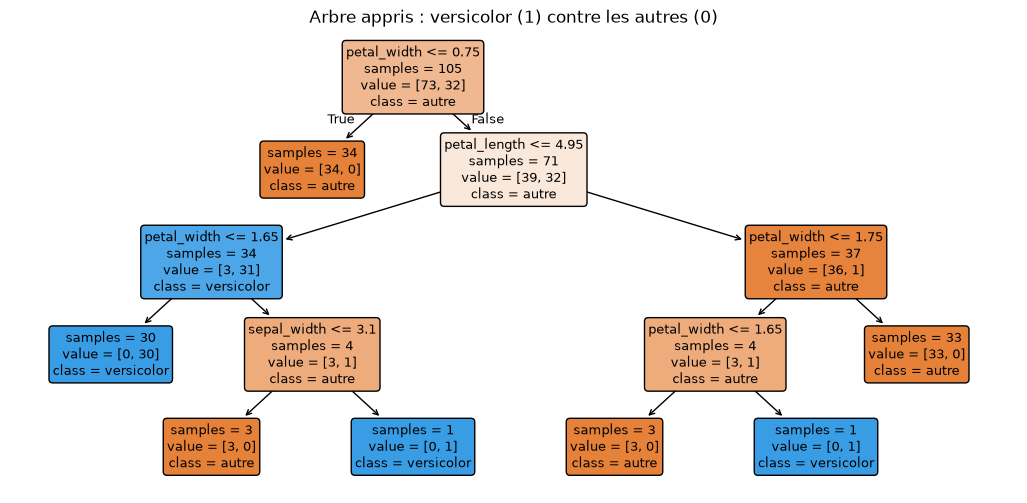

In [9]:
feat_iris = list(df_iris.columns[:-1])
fig, ax = plt.subplots(figsize=(13, 6))
plot_tree(raw_iris, feature_names=feat_iris, class_names=["autre", "versicolor"],
          filled=True, rounded=True, impurity=False, fontsize=9, ax=ax)
ax.set_title("Arbre appris : versicolor (1) contre les autres (0)")
plt.show()

### Binarisation de l'arbre

Chaque test de l'arbre devient un littéral. Le littéral positif `i` signifie « condition i vraie » (`f > s`), le littéral négatif `-i` signifie `f ≤ s`.

In [10]:
ex = Explaining.initialize(dt_iris, features_type={"numerical": Learning.DEFAULT})
lits = sorted(v[0] for v in dt_iris.map_features_to_id_binaries.values())
pd.DataFrame([{"littéral": l, "signification (+)": show(ex, (l,)), "signification (−)": show(ex, (-l,))}
              for l in lits]).set_index("littéral")

,signification (+),signification (−)
littéral,,
1,petal_width > 0.75,petal_width <= 0.75
2,petal_length > 4.95,petal_length <= 4.95
3,petal_width > 1.65,petal_width <= 1.65
4,sepal_width > 3.10,sepal_width <= 3.10
5,petal_width > 1.75,petal_width <= 1.75


In [11]:
pos = learner_iris.get_instances(dt_iris, Learning.TEST, n=1, is_correct=True, subset_predicted_classes=[1], details=True)
neg = learner_iris.get_instances(dt_iris, Learning.TEST, n=1, is_correct=True, subset_predicted_classes=[0], details=True)
pos = pos[0] if isinstance(pos, list) else pos
neg = neg[0] if isinstance(neg, list) else neg
x_pos, x_neg = pos["instance"], neg["instance"]
chosen = pd.DataFrame([x_pos, x_neg], index=[f"x⁺ (n°{pos['index']}, {df_iris.species[pos['index']]})",
                                            f"x⁻ (n°{neg['index']}, {df_iris.species[neg['index']]})"])
chosen["prédiction"] = [pos["prediction"], neg["prediction"]]
chosen

,sepal_length,sepal_width,petal_length,petal_width,prédiction
"x⁺ (n°62, versicolor)",6.0,2.2,4.0,1.0,1
"x⁻ (n°114, virginica)",5.8,2.8,5.1,2.4,0


On explique deux instances **correctement classées** du jeu de test : une versicolor ($x^+$, prédite 1) et une virginica ($x^-$, prédite 0).

### Un vérificateur indépendant

Pour ne pas croire PyXAI sur parole, on écrit un vérificateur qui travaille **directement sur l'arbre scikit-learn**. À un terme $t$ (un ensemble de littéraux) correspond une boîte de contraintes sur les attributs. On parcourt toutes les feuilles de l'arbre compatibles avec cette boîte :
- $t$ est un **impliquant** si toutes ces feuilles prédisent la même classe ;
- $t$ est **premier** si, en plus, retirer n'importe laquelle de ses conditions casse cette propriété.

Le vérificateur raisonne **au niveau des attributs**. Il commence par retirer les littéraux impliqués par d'autres sur le même attribut (`petal_width > 1.75` rend `petal_width > 1.65` superflu), puis il teste la primalité.

In [12]:
def literal_map(model):
    # littéral id -> (indice de l'attribut, seuil) ; littéral +id signifie x_f > seuil
    return {v[0]: (k[0] - 1, float(k[2])) for k, v in model.map_features_to_id_binaries.items()}

def reachable_classes(raw, model, term):
    # Classes des feuilles de l'arbre sklearn compatibles avec le terme
    lmap = literal_map(model)
    lo = {f: -np.inf for f in range(raw.n_features_in_)}
    hi = {f: np.inf for f in range(raw.n_features_in_)}
    for l in term:
        f, s = lmap[abs(l)]
        if l > 0: lo[f] = max(lo[f], s)        # x_f > s
        else:     hi[f] = min(hi[f], s)        # x_f <= s
    t, out, stack = raw.tree_, set(), [0]
    while stack:
        n = stack.pop()
        if t.children_left[n] == -1:
            out.add(int(np.argmax(t.value[n])))
            continue
        f, s = t.feature[n], t.threshold[n]
        if lo[f] < s:  stack.append(t.children_left[n])    # x_f <= s possible
        if hi[f] > s:  stack.append(t.children_right[n])   # x_f > s possible
    return out

def reduce_term(model, term):
    # Retire les littéraux impliqués par un autre littéral portant sur le même attribut
    lmap = literal_map(model)
    def implies(a, b):  # le littéral a implique-t-il le littéral b ?
        (fa, sa), (fb, sb) = lmap[abs(a)], lmap[abs(b)]
        if fa != fb or (a > 0) != (b > 0): return False
        return sa >= sb if a > 0 else sa <= sb
    return tuple(l for l in term if not any(o != l and implies(o, l) for o in term))

def is_prime_implicant(raw, model, term, cls):
    term = reduce_term(model, term)
    if reachable_classes(raw, model, term) != {cls}:
        return False
    return all(reachable_classes(raw, model, [l for l in term if l != r]) != {cls} for r in term)

<a id="4"></a>
## 4. Raison directe

In [13]:
rows = []
for name, x in [("x⁺", x_pos), ("x⁻", x_neg)]:
    ex.set_instance(x)
    d = ex.direct_reason()
    rows.append({"instance": name, "prédiction": ex.target_prediction, "représentation binaire": ex.binary_representation,
                 "raison directe (littéraux)": d, "raison directe": show(ex, d),
                 "impliquant ?": reachable_classes(raw_iris, dt_iris, d) == {ex.target_prediction},
                 "premier ?": is_prime_implicant(raw_iris, dt_iris, d, ex.target_prediction)})
pd.DataFrame(rows).set_index("instance")

,prédiction,représentation binaire,raison directe (littéraux),raison directe,impliquant ?,premier ?
instance,,,,,,
x⁺,1,"(1, -2, -3, -4, -5)","(1, -2, -3)","petal_length <= 4.95 ∧ petal_width in ]0.75, 1.65]",True,True
x⁻,0,"(1, 2, 3, -4, 5)","(1, 2, 5)",petal_length > 4.95 ∧ petal_width > 1.75,True,True


**Vérification.** La raison directe correspond bien au **chemin** suivi dans l'arbre dessiné plus haut :
- $x^+$ passe par `petal_width > 0.75`, puis `petal_length ≤ 4.95` et `petal_width ≤ 1.65` ;
- $x^-$ passe par `petal_width > 0.75`, puis `petal_length > 4.95` et `petal_width > 1.75`.

PyXAI fusionne les conditions portant sur un même attribut en un intervalle, d'où `petal_width ∈ ]0.75, 1.65]`. Une raison directe est toujours un impliquant, puisqu'elle mène à une feuille, mais pas forcément un impliquant **premier** : celle de $x^-$ contient le littéral superflu `petal_width > 0.75`, qui est déjà impliqué par `petal_width > 1.75`.

**Peut-il y avoir plusieurs raisons directes ?** **Non.** Un arbre de décision est déterministe : chaque instance suit **un unique chemin** de la racine à une feuille, donc sa raison directe est unique.

<a id="5"></a>
## 5. Raisons suffisantes

In [14]:
def explain_sufficient(ex, x, raw, model):
    ex.set_instance(x)
    one = ex.sufficient_reason(n=1)
    all_sr = as_list(ex.sufficient_reason(n=Explaining.ALL))
    print(f"Prédiction = {ex.target_prediction}")
    print(f"  Une raison suffisante       : {show(ex, one)}")
    print(f"  Toutes ({len(all_sr)}) :")
    for r in all_sr:
        print(f"     {str(r):<14} {show(ex, r):<48} taille attributs={len(reduce_term(model, r))}  "
              f"PyXAI={ex.is_sufficient_reason(r)}  vérif. indépendante={is_prime_implicant(raw, model, r, ex.target_prediction)}")
    return all_sr

print("=== x⁺ ==="); sr_pos = explain_sufficient(ex, x_pos, raw_iris, dt_iris)
print("\n=== x⁻ ==="); sr_neg = explain_sufficient(ex, x_neg, raw_iris, dt_iris)

=== x⁺ ===
Prédiction = 1
  Une raison suffisante       : petal_length <= 4.95 ∧ petal_width in ]0.75, 1.65]
  Toutes (1) :
     (1, -2, -3)    petal_length <= 4.95 ∧ petal_width in ]0.75, 1.65] taille attributs=3  PyXAI=True  vérif. indépendante=True

=== x⁻ ===
Prédiction = 0
  Une raison suffisante       : petal_length > 4.95 ∧ petal_width > 1.75
  Toutes (2) :
     (2, 5)         petal_length > 4.95 ∧ petal_width > 1.75         taille attributs=2  PyXAI=True  vérif. indépendante=True
     (3, -4, 5)     sepal_width <= 3.10 ∧ petal_width > 1.75         taille attributs=2  PyXAI=True  vérif. indépendante=True


**Interprétation.**
- Pour $x^+$, il y a une seule raison suffisante, et elle coïncide avec la raison directe : aucun des trois tests du chemin ne peut être omis. La feuille versicolor est entourée de feuilles « autre » de tous les côtés.
- Pour $x^-$, il y a **deux** raisons suffisantes :
  - `petal_length > 4.95 ∧ petal_width > 1.75` : c'est la raison directe débarrassée du littéral redondant `petal_width > 0.75` ;
  - `sepal_width ≤ 3.10 ∧ petal_width > 1.75` : elle utilise un littéral **qui n'est pas sur le chemin** de $x^-$. Avec ces deux conditions, *quel que soit* `petal_length`, toutes les branches de l'arbre mènent à la classe 0.

Les deux vérifications, celle de PyXAI et la nôtre, confirment qu'il s'agit d'impliquants premiers.

**Subtilité : niveau booléen ou niveau des attributs.** PyXAI renvoie la seconde raison sous la forme de **3 littéraux** `(3, -4, 5)`, alors qu'elle ne compte que **2 conditions** sur les attributs : le littéral 3 (`petal_width > 1.65`) est impliqué par le littéral 5 (`petal_width > 1.75`). Les deux variables booléennes ne sont pas indépendantes. PyXAI les traite comme des variables distinctes reliées par la théorie, et `to_features` fusionne les conditions à l'affichage. Notre vérificateur, qui réduit d'abord le terme, confirme que la version à 2 conditions est bien un impliquant premier.

**Une instance peut-elle avoir plusieurs raisons suffisantes ?** **Oui**, comme $x^-$ (et $(1,1,1,1)$ dans l'arbre des orchidées). Une raison suffisante n'est pas contrainte à suivre le chemin : elle doit seulement « couvrir » $x$ et être un impliquant premier. Il peut y en avoir un nombre exponentiel en la taille de l'arbre, ce que la partie 9 met en évidence.

<a id="6"></a>
## 6. Raisons suffisantes minimales

In [15]:
for name, x in [("x⁺", x_pos), ("x⁻", x_neg)]:
    ex.set_instance(x)
    msr = as_list(ex.minimal_sufficient_reason(n=Explaining.ALL))
    print(f"{name} : {len(msr)} raison(s) suffisante(s) minimale(s) → " + " | ".join(show(ex, r) for r in msr))

x⁺ : 1 raison(s) suffisante(s) minimale(s) → petal_length <= 4.95 ∧ petal_width in ]0.75, 1.65]
x⁻ : 1 raison(s) suffisante(s) minimale(s) → petal_length > 4.95 ∧ petal_width > 1.75


Pour ces deux instances, PyXAI trouve une raison suffisante minimale **unique**. Pour $x^-$, les deux raisons suffisantes comptent 2 et 3 *littéraux* : PyXAI minimise le nombre de littéraux booléens. **Au niveau des attributs**, en revanche, elles comptent toutes les deux 2 conditions, et $x^-$ a donc deux explications minimales d'un point de vue « humain ». Le critère de minimalité dépend de la représentation.

On cherche maintenant des instances qui ont plusieurs raisons minimales **au sens de PyXAI**.

### 6.1 Construction à la main

On construit l'arbre de $f = (x_1 \wedge x_2) \vee (x_3 \wedge x_4)$. Pour $x = (1,1,1,1)$, les deux termes $x_1x_2$ et $x_3x_4$ suffisent chacun et ont la même taille : on obtient **deux** raisons suffisantes minimales par construction.

In [16]:
def g():  # sous-arbre x3 ∧ x4
    return Builder.DecisionNode(3, left=0, right=Builder.DecisionNode(4, left=0, right=1))
root = Builder.DecisionNode(1, left=g(), right=Builder.DecisionNode(2, left=g(), right=1))
tree_or = Builder.DecisionTree(4, root, force_features_equal_to_binaries=True)
ex_or = Explaining.initialize(tree_or, instance=(1, 1, 1, 1))
print("prédiction :", ex_or.target_prediction)
print("raison directe :", ex_or.direct_reason())
print("raisons suffisantes :", ex_or.sufficient_reason(n=Explaining.ALL))
print("raisons suffisantes minimales :", ex_or.minimal_sufficient_reason(n=Explaining.ALL))
ex_or.set_instance((0, 1, 0, 1))
print("\nPour (0,1,0,1), classe 0 : raisons minimales :", ex_or.minimal_sufficient_reason(n=Explaining.ALL))

prédiction : 1
raison directe : (1, 2)
raisons suffisantes : ((3, 4), (1, 2))
raisons suffisantes minimales : ((3, 4), (1, 2))

Pour (0,1,0,1), classe 0 : raisons minimales : ((-1, -3),)


### 6.2 Recherche systématique sur l'arbre Iris

On construit une **grille d'instances synthétiques** : pour chaque attribut utilisé, on prend une valeur dans chacun des intervalles délimités par les seuils de l'arbre. On couvre ainsi toutes les combinaisons de littéraux possibles. Pour chaque point, on calcule toutes les raisons suffisantes minimales.

In [17]:
def search_multiple_minimal(raw, e):
    t = raw.tree_
    grids = []
    for f in range(4):
        th = sorted(set(t.threshold[t.feature == f]))
        mid = df_iris.iloc[:, f].median()
        if not th:
            grids.append([mid]); continue
        pts = [th[0] - 0.5] + [(a + b) / 2 for a, b in zip(th, th[1:])] + [th[-1] + 0.5]
        grids.append(pts)
    found = []
    for point in itertools.product(*grids):
        e.set_instance(np.array(point))
        msr = as_list(e.minimal_sufficient_reason(n=Explaining.ALL))
        if len(msr) > 1:
            found.append((point, e.target_prediction, [show(e, r) for r in msr]))
    return found, int(np.prod([len(g) for g in grids]))

found, n_pts = search_multiple_minimal(raw_iris, ex)
print(f"{n_pts} points testés, {len(found)} instance(s) avec ≥ 2 raisons suffisantes minimales :")
for point, p, rs in found:
    print(f"   x = {tuple(round(float(v), 2) for v in point)}  (classe prédite {p})")
    for r in rs:
        print("        ", r)

16 points testés, 3 instance(s) avec ≥ 2 raisons suffisantes minimales :
   x = (5.8, 2.6, 4.45, 2.25)  (classe prédite 0)
         sepal_width <= 3.10 ∧ petal_width > 1.75
         sepal_width <= 3.10 ∧ petal_length <= 4.95 ∧ petal_width > 1.65
   x = (5.8, 3.6, 4.45, 1.2)  (classe prédite 1)
         sepal_width > 3.10 ∧ petal_length <= 4.95 ∧ petal_width > 0.75
         petal_length <= 4.95 ∧ petal_width in ]0.75, 1.65]
   x = (5.8, 3.6, 5.45, 1.7)  (classe prédite 1)
         sepal_width > 3.10 ∧ petal_width in ]1.65, 1.75]
         petal_length > 4.95 ∧ petal_width in ]1.65, 1.75]


**Conclusion.** **Oui**, il peut y avoir plusieurs raisons suffisantes minimales : c'est le cas dès que deux « morceaux » de l'arbre, de même taille, garantissent chacun la prédiction, comme dans $f = x_1x_2 \vee x_3x_4$.

Sur l'arbre Iris, la recherche exhaustive (sur 16 régions) trouve **3 instances construites** qui ont chacune deux raisons minimales. Par exemple, $x = (5.8,\ 3.6,\ 5.45,\ 1.7)$ est classée versicolor **soit** parce que `sepal_width > 3.10`, **soit** parce que `petal_length > 4.95`, à chaque fois avec `petal_width ∈ ]1.65, 1.75]`.

Ces instances sont **synthétiques** : une fleur au sépale très large et au pétale long est peu plausible. C'est une limite connue des explications formelles : elles raisonnent sur tout l'espace des entrées, pas seulement sur les données réalistes.

<a id="7"></a>
## 7. Explications contrastives et dualité

Une explication contrastive répond à la question « **pourquoi pas l'autre classe ?** ». C'est un ensemble minimal de caractéristiques de $x$ qu'il suffit de modifier pour que la prédiction puisse changer.

In [18]:
rows = []
for name, x in [("x⁺", x_pos), ("x⁻", x_neg)]:
    ex.set_instance(x)
    cr = as_list(ex.contrastive_reason(n=Explaining.ALL))
    sr = as_list(ex.sufficient_reason(n=Explaining.ALL))
    min_size = min(len(c) for c in cr)
    for c in cr:
        # vérification : t_x \ c ne doit PAS être un impliquant
        rest = [l for l in ex.binary_representation if l not in c]
        rows.append({"instance": name, "contrastive": c, "à modifier": show(ex, c, contrastive=True),
                     "minimale (taille)": len(c) == min_size,
                     "PyXAI ok": ex.is_contrastive_reason(c),
                     "contrastive au niveau attributs (vérif.)": reachable_classes(raw_iris, dt_iris, rest) != {ex.target_prediction}})
    print(f"{name} : SR = {sr}  |  hitting sets minimaux des SR = {sorted(map(tuple, minimal_hitting_sets(sr)))}"
          f"  |  égaux aux contrastives : {minimal_hitting_sets(sr) == set(map(frozenset, cr))}")
pd.DataFrame(rows)

x⁺ : SR = [(1, -2, -3)]  |  hitting sets minimaux des SR = [(-3,), (-2,), (1,)]  |  égaux aux contrastives : True
x⁻ : SR = [(2, 5), (3, -4, 5)]  |  hitting sets minimaux des SR = [(2, -4), (2, 3), (5,)]  |  égaux aux contrastives : True


,instance,contrastive,à modifier,minimale (taille),PyXAI ok,contrastive au niveau attributs (vérif.)
0,x⁺,"(1,)",petal_width > 0.75,True,True,True
1,x⁺,"(-3,)",petal_width <= 1.65,True,True,True
2,x⁺,"(-2,)",petal_length <= 4.95,True,True,True
3,x⁻,"(5,)",petal_width > 1.75,True,True,True
4,x⁻,"(2, 3)",petal_length > 4.95 ∧ petal_width > 1.65,False,True,False
5,x⁻,"(2, -4)",sepal_width <= 3.10 ∧ petal_length > 4.95,False,True,True


**Interprétation.**
- Pour $x^+$ (versicolor), il y a trois explications contrastives d'un seul littéral. Modifier *une seule* des trois conditions du chemin, `petal_width > 0.75`, `petal_width ≤ 1.65` ou `petal_length ≤ 4.95`, suffit à faire sortir l'instance de la feuille versicolor. On retrouve une feuille « étroite », entourée d'autres classes.
- Pour $x^-$ (virginica), l'explication contrastive minimale est `petal_width > 1.75` : si l'on réduit la largeur du pétale, l'instance peut basculer. Les deux autres contrastives demandent de changer deux caractéristiques à la fois.
- **Nuance, encore due à la représentation.** La contrastive `(2, 3)` est valide au niveau booléen, mais pas au niveau des attributs : rendre `petal_width ≤ 1.65` force aussi `petal_width ≤ 1.75`, donc on modifie en réalité le littéral 5, et l'on retombe sur la contrastive `(5,)`. Notre vérificateur la rejette pour cette raison. Au niveau des attributs, $x^-$ a donc deux contrastives : `petal_width ≤ 1.75`, ou bien changer à la fois `petal_length` et `sepal_width`. Ce sont exactement les hitting sets minimaux des deux raisons suffisantes réduites $\{2,5\}$ et $\{-4,5\}$.

**Relation avec les raisons suffisantes : la dualité par hitting sets.** Chaque explication contrastive **intersecte chaque** raison suffisante. C'est logique : si une contrastive $c$ évitait une raison suffisante $s$, on pourrait modifier $c$ en gardant $s$ vraie, et la classe ne pourrait pas changer. On vérifie expérimentalement l'égalité exacte :

$$\text{Contrastives}(x) = \text{MinHittingSets}(\text{SR}(x)) \qquad\text{et}\qquad \text{SR}(x) = \text{MinHittingSets}(\text{Contrastives}(x))$$

Pour $x^+$, l'unique raison suffisante $\{1,-2,-3\}$ a pour hitting sets minimaux les trois singletons $\{1\},\{-2\},\{-3\}$, qui sont exactement les trois contrastives. Pour $x^-$, les hitting sets minimaux de $\{2,5\}$ et $\{3,-4,5\}$ sont $\{5\}, \{2,3\}, \{2,-4\}$.

**Conséquence pratique.** Sur un arbre, il est facile de calculer *toutes* les contrastives : elles se lisent sur les chemins menant à l'autre classe. On peut ensuite en déduire les raisons suffisantes par dualité, et une raison suffisante minimale correspond à un hitting set minimum des contrastives.

<a id="8"></a>
## 8. Données plus grandes : UCI Adult

Le jeu [UCI Adult](https://archive.ics.uci.edu/dataset/2/adult) (recensement américain de 1994) compte 30 162 individus après suppression des valeurs manquantes. La tâche consiste à prédire si le revenu dépasse 50 K$/an. On a 5 attributs numériques et 7 catégoriels ; ces derniers sont encodés en one-hot, et la théorie du domaine de PyXAI impose qu'un seul indicateur par variable catégorielle soit vrai.

On retire `fnlwgt`, un poids d'échantillonnage sans signification individuelle, et `education`, redondant avec `education_num`.

In [19]:
ADULT_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
if not os.path.exists("data/adult.data"):
    urllib.request.urlretrieve(ADULT_URL, "data/adult.data")

cols = ["age", "workclass", "fnlwgt", "education", "education_num", "marital_status", "occupation",
        "relationship", "race", "sex", "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"]
adult = (pd.read_csv("data/adult.data", names=cols, skipinitialspace=True, na_values="?")
           .dropna().drop(columns=["fnlwgt", "education"]))
CATS = ["workclass", "marital_status", "occupation", "relationship", "race", "native_country"]

pre_adult = Learning.TabularPreprocessor(adult, target_feature="income", problem_type=Learning.CLASSIFICATION,
                                         classification_type=Learning.BINARY_CLASS)
pre_adult.set_categorical_features(features=CATS + ["sex"])
pre_adult.set_numerical_features({c: None for c in ["age", "education_num", "capital_gain", "capital_loss", "hours_per_week"]})
with quiet():
    pre_adult.process()
    pre_adult.export("adult", output_directory="data")

adult_enc = pd.read_csv("data/adult.csv")
print(f"{adult.shape[0]} individus, {adult.shape[1]-1} attributs → {adult_enc.shape[1]-1} colonnes après encodage")
print("Classe 1 (>50K) :", f"{adult_enc.iloc[:, -1].mean():.1%}")

# Types des attributs pour la théorie du domaine (le fichier .types exporté par PyXAI 2.0.1
# n'est pas relu correctement, on construit donc le dictionnaire explicitement)
enc_cols = list(adult_enc.columns[:-1])
ADULT_TYPES = {"numerical": Learning.DEFAULT, "binary": ["sex"],
               "categorical": {c + "*": [x[len(c) + 1:] for x in enc_cols if x.startswith(c + "_")] for c in CATS}}

30162 individus, 12 attributs → 86 colonnes après encodage
Classe 1 (>50K) : 24.9%


In [20]:
def train_adult(depth):
    learner = Learning.Scikitlearn("data/adult.csv", problem_type=Learning.CLASSIFICATION)
    model = learner.evaluate(splitting_method=Learning.HOLD_OUT, model_type=Learning.DT,
                             model_parameters={"random_state": SEED, "max_depth": depth},
                             splitting_parameters={"random_state": SEED, "test_size": 0.3})
    e = Explaining.initialize(model, features_type=ADULT_TYPES)
    return learner, model, e

learner_a, dt_a, ex_a = train_adult(8)
ma = learner_a.get_details()[0]["metrics"]
print(f"Arbre de profondeur 8 : {dt_a.n_nodes()} nœuds, {len(dt_a.map_features_to_id_binaries)} variables booléennes")
print(f"Accuracy = {ma['accuracy']:.2f} %, F1 = {ma['f1_score']:.2f} %")

Arbre de profondeur 8 : 247 nœuds, 92 variables booléennes
Accuracy = 83.07 %, F1 = 57.49 %


In [21]:
pa = learner_a.get_instances(dt_a, Learning.TEST, n=1, is_correct=True, subset_predicted_classes=[1])
na = learner_a.get_instances(dt_a, Learning.TEST, n=1, is_correct=True, subset_predicted_classes=[0])
for name, (x, p) in [("x⁺ (>50K)", pa), ("x⁻ (≤50K)", na)]:
    ex_a.set_instance(x)
    d = ex_a.direct_reason()
    sr = as_list(ex_a.sufficient_reason(n=Explaining.ALL))
    msr = as_list(ex_a.minimal_sufficient_reason(n=Explaining.ALL))
    cr = as_list(ex_a.contrastive_reason(n=Explaining.ALL))
    hit_ok = all(set(c) & set(s) for c in cr for s in sr)
    print(f"===== {name} =====")
    print(f"raison directe ({len(d)} littéraux) : {show(ex_a, d)}")
    print(f"#raisons suffisantes = {len(sr)}  (taille min {min(map(len, sr))}, max {max(map(len, sr))})")
    print(f"#raisons suffisantes minimales = {len(msr)} ; exemple : {show(ex_a, msr[0])}")
    print(f"#explications contrastives = {len(cr)} ; les plus petites :")
    for c in cr[:3]:
        print("     changer :", show(ex_a, c, contrastive=True))
    print(f"chaque contrastive intersecte chaque raison suffisante : {hit_ok}\n")

===== x⁺ (>50K) =====
raison directe (8 littéraux) : age > 33.5 ∧ education_num in ]5.0, 12.5] ∧ sex = 1 ∧ capital_gain <= 5095.5 ∧ capital_loss in ]1881.5, 1978.5]
#raisons suffisantes = 160  (taille min 8, max 25)
#raisons suffisantes minimales = 1 ; exemple : age > 33.5 ∧ education_num in ]5.0, 12.5] ∧ sex = 1 ∧ capital_gain <= 5095.5 ∧ capital_loss in ]1881.5, 1978.5]
#explications contrastives = 26 ; les plus petites :
     changer : capital_loss > 1820.5
     changer : capital_loss > 1881.5
     changer : education_num > 5.0
chaque contrastive intersecte chaque raison suffisante : True



===== x⁻ (≤50K) =====
raison directe (8 littéraux) : age > 33.5 ∧ education_num in ]8.5, 9.5] ∧ sex = 0 ∧ capital_gain <= 5095.5 ∧ capital_loss <= 1805.0 ∧ native_country != China
#raisons suffisantes = 968  (taille min 7, max 21)
#raisons suffisantes minimales = 1 ; exemple : age > 33.5 ∧ education_num <= 9.5 ∧ sex = 0 ∧ capital_gain <= 5095.5 ∧ capital_loss <= 1805.0 ∧ native_country != China
#explications contrastives = 22 ; les plus petites :
     changer : native_country != China
     changer : capital_loss <= 1805.0
     changer : capital_gain <= 5095.5
chaque contrastive intersecte chaque raison suffisante : True



**Observations.**
- Sur un jeu réel, une instance a facilement **des centaines, voire des milliers** de raisons suffisantes, contre une seule raison directe et quelques dizaines de contrastives.
- Les raisons suffisantes minimales sont **courtes** (quelques littéraux), nettement plus que la raison directe. Elles sont donc bien plus lisibles pour un utilisateur.
- Les contrastives se lisent comme des **contrefactuels** actionnables, par exemple « si `marital_status` n'était pas *Married-civ-spouse*, la prédiction pourrait changer ».
- La propriété d'intersection entre contrastives et raisons suffisantes reste vérifiée.
- La redondance du niveau booléen est plus visible encore : `capital_loss > 1820.5` et `capital_loss > 1881.5` apparaissent comme deux contrastives distinctes alors qu'elles portent sur le même attribut. Un filtrage « au niveau attributs » serait utile avant de présenter les explications à un utilisateur.

<a id="9"></a>
## 9. Temps de calcul et nombre d'explications

**Protocole.** Pour des arbres de profondeur 3 à 12 appris sur Adult, on tire au hasard 10 instances de test prédites positives et 10 prédites négatives. Pour chacune, on mesure :
- le temps de la raison directe, d'une raison suffisante, d'une raison suffisante minimale (solveur) et de **toutes** les contrastives ;
- le nombre de raisons suffisantes, obtenu par comptage via compilation ;
- le temps d'énumération de **toutes** les raisons suffisantes. On ne le mesure que jusqu'à la profondeur 8 : au-delà, l'énumération prend plusieurs dizaines de secondes par instance.

In [22]:
def timed(f):
    t = time.perf_counter(); r = f(); return r, time.perf_counter() - t

records = []
for depth in [3, 4, 6, 8, 10, 12]:
    learner, model, e = train_adult(depth)
    acc = learner.get_details()[0]["metrics"]["accuracy"]
    sample = (learner.get_instances(model, Learning.TEST, n=10, subset_predicted_classes=[1], seed=42) +
              learner.get_instances(model, Learning.TEST, n=10, subset_predicted_classes=[0], seed=42))
    for x, p in sample:
        e.set_instance(x)
        _, t_dir = timed(e.direct_reason)
        _, t_sr1 = timed(lambda: e.sufficient_reason(n=1))
        _, t_msr = timed(lambda: e.minimal_sufficient_reason(n=1))
        cr, t_cr = timed(lambda: as_list(e.contrastive_reason(n=Explaining.ALL)))
        n_sr, t_cnt = timed(lambda: count_sr(e))
        t_enum = timed(lambda: e.sufficient_reason(n=Explaining.ALL))[1] if depth <= 8 else np.nan
        records.append(dict(depth=depth, nodes=model.n_nodes(), accuracy=acc, classe=int(p),
                            n_sr=n_sr, n_contrastives=len(cr), t_direct=t_dir, t_one_sr=t_sr1,
                            t_min_sr=t_msr, t_all_contrastives=t_cr, t_count_sr=t_cnt, t_enum_all_sr=t_enum))
res = pd.DataFrame(records)

agg = res.groupby("depth").agg(noeuds=("nodes", "first"), accuracy=("accuracy", "first"),
                               SR_median=("n_sr", "median"), SR_max=("n_sr", "max"),
                               contr_median=("n_contrastives", "median"), contr_max=("n_contrastives", "max"),
                               t_min_sr_ms=("t_min_sr", lambda s: 1000 * s.mean()),
                               t_contr_ms=("t_all_contrastives", lambda s: 1000 * s.mean()),
                               t_enum_SR_s=("t_enum_all_sr", "mean"))
agg.round(2)

,noeuds,accuracy,SR_median,SR_max,contr_median,contr_max,t_min_sr_ms,t_contr_ms,t_enum_SR_s
depth,,,,,,,,,
3,15,79.75,2.0,3,2.5,4,1.24,0.27,0.00
4,27,81.80,2.0,4,3.0,6,1.45,0.31,0.00
6,89,82.78,6.0,63,7.0,12,2.44,0.64,0.00
8,247,83.07,522.0,13599,22.0,25,5.25,1.93,0.26
10,497,83.00,2225.0,9685266,33.0,62,10.79,4.74,NaN
12,881,82.54,19690.0,230300928,52.5,111,22.03,11.79,NaN


In [23]:
# Nombre médian de raisons suffisantes par classe prédite
res.pivot_table(index="depth", columns="classe", values="n_sr", aggfunc="median").rename(
    columns={0: "classe 0 (≤50K)", 1: "classe 1 (>50K)"})

classe,classe 0 (≤50K),classe 1 (>50K)
depth,,
3,1.0,2.5
4,2.0,2.5
6,27.0,4.5
8,1998.0,13.0
10,545677.0,52.5
12,4588499.5,253.5


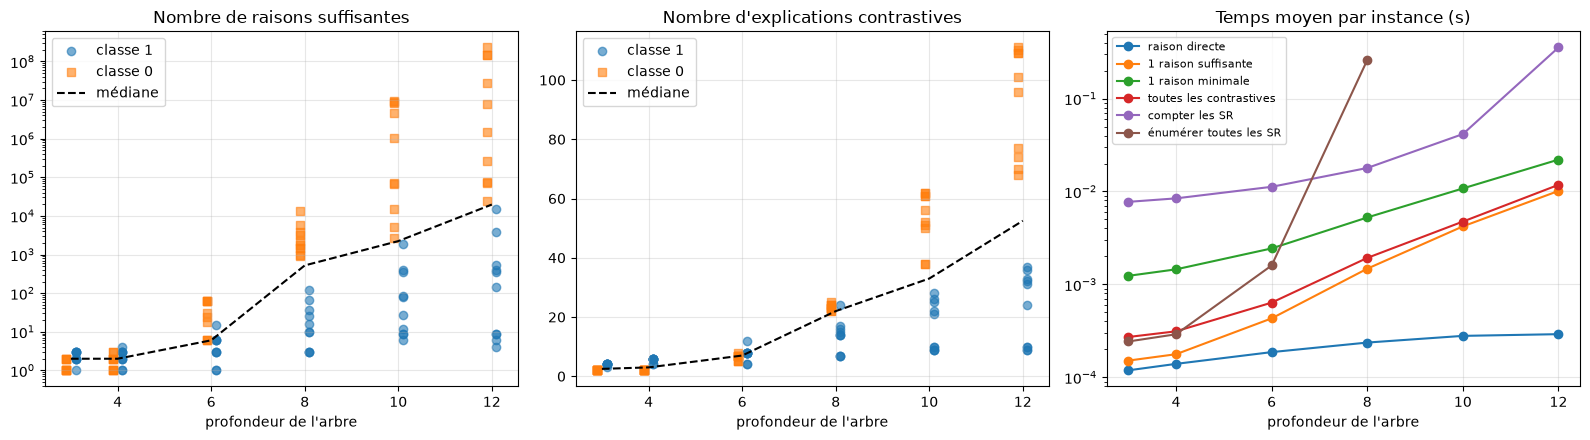

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for cls, mk in [(1, "o"), (0, "s")]:
    sub = res[res.classe == cls]
    axes[0].scatter(sub.depth + (0.1 if cls else -0.1), sub.n_sr, marker=mk, alpha=.6, label=f"classe {cls}")
axes[0].plot(agg.index, agg.SR_median, "k--", label="médiane")
axes[0].set_yscale("log"); axes[0].set_title("Nombre de raisons suffisantes"); axes[0].legend()

for cls, mk in [(1, "o"), (0, "s")]:
    sub = res[res.classe == cls]
    axes[1].scatter(sub.depth + (0.1 if cls else -0.1), sub.n_contrastives, marker=mk, alpha=.6, label=f"classe {cls}")
axes[1].plot(agg.index, agg.contr_median, "k--", label="médiane")
axes[1].set_title("Nombre d'explications contrastives"); axes[1].legend()

tm = res.groupby("depth")[["t_direct", "t_one_sr", "t_min_sr", "t_all_contrastives", "t_count_sr", "t_enum_all_sr"]].mean()
for col, lab in [("t_direct", "raison directe"), ("t_one_sr", "1 raison suffisante"), ("t_min_sr", "1 raison minimale"),
                 ("t_all_contrastives", "toutes les contrastives"), ("t_count_sr", "compter les SR"),
                 ("t_enum_all_sr", "énumérer toutes les SR")]:
    axes[2].plot(tm.index, tm[col], marker="o", label=lab)
axes[2].set_yscale("log"); axes[2].set_title("Temps moyen par instance (s)"); axes[2].legend(fontsize=8)
for a in axes: a.set_xlabel("profondeur de l'arbre"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Analyse.**
- **Le nombre de raisons suffisantes explose** avec la profondeur : quelques unités en profondeur 3, puis des dizaines de milliers (et plus pour certaines instances) au-delà de 10. La croissance est **exponentielle** (l'axe est logarithmique). Les énumérer toutes devient vite impraticable, ce qui confirme le résultat théorique.
- **Le nombre de contrastives reste modéré** et croît à peu près linéairement avec la taille de l'arbre. C'est cohérent avec la théorie : elles sont bornées par le nombre de chemins vers l'autre classe, et toutes se calculent en temps polynomial sur un arbre de décision.
- **Les temps** : la raison directe, une raison suffisante et toutes les contrastives se calculent en quelques millisecondes. La raison suffisante minimale fait appel à un solveur (NP-difficile en général), mais reste rapide à cette échelle. Compter les raisons suffisantes par compilation coûte peu, alors que les énumérer coûte cher : la différence entre compter et énumérer est flagrante.
- **Asymétrie entre classes** : les instances positives (>50K, classe minoritaire) ont **beaucoup moins** de raisons suffisantes. À la profondeur 12, on mesure une médiane d'environ 250 pour la classe 1 contre plusieurs millions pour la classe 0. Les régions positives de l'arbre sont étroites et peu nombreuses, alors que la classe majoritaire peut être « garantie » par d'innombrables combinaisons de conditions.
- **Compromis précision / explicabilité** : au-delà de la profondeur 6 à 8, l'accuracy ne progresse plus (elle baisse même légèrement à cause du sur-apprentissage), alors que la complexité des explications explose. Un arbre peu profond est donc **à la fois meilleur et plus explicable** ici.

<a id="10"></a>
## 10. Bonus : prédire avec des raisons suffisantes

**Idée.** Pour chaque instance d'apprentissage, on calcule une raison suffisante minimale : elle donne une règle `SI t ALORS classe`. Pour classer un exemple de test, on cherche les règles dont le terme est satisfait par l'exemple, c'est-à-dire inclus dans sa représentation binaire, et on vote. Si aucune règle ne s'applique, on prédit la classe majoritaire.

In [25]:
def sr_rule_classifier(learner, model, e, csv, n_train=None, seed=SEED):
    det = learner.get_details()[0]
    data = pd.read_csv(csv)
    X, y = data.iloc[:, :-1], data.iloc[:, -1].values
    tr = list(det["train_index"]); te = list(det["test_index"])
    if n_train is not None:
        tr = random.Random(seed).sample(tr, min(n_train, len(tr)))
    rules = {}
    for i in tr:
        e.set_instance(X.loc[i])
        r = e.minimal_sufficient_reason(n=1)
        rules[frozenset(r)] = e.target_prediction
    default = Counter(y[tr]).most_common(1)[0][0]
    covered = correct_cov = correct_all = tree_ok = conflicts = 0
    for i in te:
        e.set_instance(X.loc[i]); B = set(e.binary_representation)
        votes = [c for t, c in rules.items() if t <= B]
        pred = Counter(votes).most_common(1)[0][0] if votes else default
        conflicts += len(set(votes)) > 1
        covered += bool(votes)
        correct_cov += bool(votes) and pred == y[i]
        correct_all += pred == y[i]
        tree_ok += e.target_prediction == y[i]
    n = len(te)
    return dict(n_train_utilisés=len(tr), n_regles_distinctes=len(rules), couverture=covered / n,
                acc_sur_couverts=correct_cov / max(covered, 1), acc_regles_avec_defaut=correct_all / n,
                acc_arbre=tree_ok / n, conflits=conflicts)

bonus = [dict(jeu="Iris (versicolor)", **sr_rule_classifier(learner_iris, dt_iris, ex, "data/iris_1_vs_others.csv"))]
for n_tr in [50, 200, 1000]:
    bonus.append(dict(jeu="Adult (prof. 8)", **sr_rule_classifier(learner_a, dt_a, ex_a, "data/adult.csv", n_train=n_tr)))
pd.DataFrame(bonus).round(3)

,jeu,n_train_utilisés,n_regles_distinctes,couverture,acc_sur_couverts,acc_regles_avec_defaut,acc_arbre,conflits
0,Iris (versicolor),105,8,1.000,0.978,0.978,0.978,0
1,Adult (prof. 8),50,21,0.925,0.836,0.808,0.831,0
2,Adult (prof. 8),200,43,0.977,0.830,0.818,0.831,0
3,Adult (prof. 8),1000,71,0.990,0.831,0.828,0.831,0


**Commentaire.**
- **Aucun conflit** : une raison suffisante est un impliquant de l'arbre. Dès qu'un exemple satisfait une règle, la classe votée est *exactement* celle de l'arbre. Sur les exemples couverts, la précision des règles est donc égale à celle de l'arbre : les règles ne « généralisent » pas mieux que lui, elles en sont une **réécriture fidèle et compacte**.
- **La couverture** est le vrai critère. Une seule raison minimale par instance d'entraînement ne couvre pas tout l'espace, et les exemples non couverts tombent sur la règle par défaut. La couverture augmente avec le nombre d'instances d'entraînement expliquées, alors que le nombre de règles distinctes reste bien inférieur au nombre d'instances : beaucoup d'instances partagent la même explication courte.
- **Intérêt** : on obtient un **classifieur à base de règles courtes, certifiées** (chaque règle est prouvée correcte vis-à-vis du modèle), ce qui en fait un résumé global interprétable du modèle. Sur Adult, **71 règles distinctes**, issues de 1 000 instances expliquées, couvrent 99 % des exemples de test et donnent la même accuracy que l'arbre (83 %).
- **Limite** : ces règles héritent des erreurs de l'arbre (fidélité au modèle et non à la réalité). Les choisir *minimales* favorise la concision, mais d'autres préférences existent : PyXAI propose `preferred_sufficient_reason`, par exemple pour éviter des attributs sensibles comme `sex` ou `race`.

<a id="11"></a>
## 11. Conclusion

| Explication | Unicité | Coût sur un arbre | Ce qu'elle dit |
|---|---|---|---|
| Raison directe | unique | linéaire | « voici le chemin suivi » (souvent redondant) |
| Raison suffisante | plusieurs, **nombre exponentiel** | une : polynomial ; toutes : exponentiel | « ces caractéristiques suffisent à garantir la décision » |
| Raison suffisante minimale | parfois plusieurs | NP-difficile (solveur), rapide en pratique ici | l'explication abductive la plus courte |
| Explication contrastive | plusieurs, **nombre polynomial** | toutes en temps polynomial | « il suffirait de changer ceci pour que la décision puisse changer » |

**À retenir**
1. Les explications formelles sont **prouvées correctes**. Nous les avons recoupées avec un vérificateur indépendant écrit directement sur l'arbre scikit-learn.
2. La **dualité par hitting sets** entre raisons suffisantes et contrastives est vérifiée exactement sur tous nos exemples.
3. En pratique, le nombre de raisons suffisantes **explose** avec la taille du modèle, alors que les contrastives restent peu nombreuses. Les arbres peu profonds offrent ici le meilleur compromis entre précision et explicabilité.
4. Les raisons suffisantes minimales fournissent des **règles courtes et certifiées**, utilisables comme résumé global du modèle.

**Compétences mobilisées** : Python, scikit-learn, PyXAI, logique propositionnelle (impliquants premiers, CNF/DNF, hitting sets), prétraitement de données catégorielles et numériques, protocole expérimental et analyse de complexité.

*Références : Audemard, Bellart, Bounia, Koriche, Lagniez, Marquis. On the explanatory power of Boolean decision trees, DKE 2022 · Darwiche & Hirth, On the reasons behind decisions, ECAI 2020 · Ignatiev, Narodytska, Asher, Marques-Silva, From contrastive to abductive explanations and back again, AI\*IA 2020 · Documentation PyXAI.*